# Ejemplo de segmentación por color


# Librarias

In [12]:
import numpy as np
from  cv2 import imread
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

# Leemos la imágen

In [13]:
!wget https://www.dropbox.com/scl/fi/2wyj3x4hv7jtx3gnrn16l/flowers.jpg?rlkey=fd9h6zmc0gxbqaft10i9zeaer&st=3z1pw4yv&dl=0
!mv flowers.jpg?rlkey=fd9h6zmc0gxbqaft10i9zeaer flowers.jpg

--2026-06-18 22:23:32--  https://www.dropbox.com/scl/fi/2wyj3x4hv7jtx3gnrn16l/flowers.jpg?rlkey=fd9h6zmc0gxbqaft10i9zeaer
Resolving www.dropbox.com (www.dropbox.com)... 162.125.13.18, 2620:100:6031:18::a27d:5112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.13.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc275ea81c537956f74d960d5ba6.dl.dropboxusercontent.com/cd/0/inline/DCrlqYvBUPXy1sD1RoXwFpPDLn6fCO1gxkA3XfOmTOsq1gO_1M8Ls9DcZFjH4kSdfOevc8j0m8lTTtYSyJG0WwtkrZKpkA0Obl9CEFzTEtmzx_61Rd3NEO0nIVa9mxEpdz4/file# [following]
--2026-06-18 22:23:33--  https://uc275ea81c537956f74d960d5ba6.dl.dropboxusercontent.com/cd/0/inline/DCrlqYvBUPXy1sD1RoXwFpPDLn6fCO1gxkA3XfOmTOsq1gO_1M8Ls9DcZFjH4kSdfOevc8j0m8lTTtYSyJG0WwtkrZKpkA0Obl9CEFzTEtmzx_61Rd3NEO0nIVa9mxEpdz4/file
Resolving uc275ea81c537956f74d960d5ba6.dl.dropboxusercontent.com (uc275ea81c537956f74d960d5ba6.dl.dropboxusercontent.com)... 162.125.13.15, 2620:100:6028:15::a27d:470f
Connecting to uc2

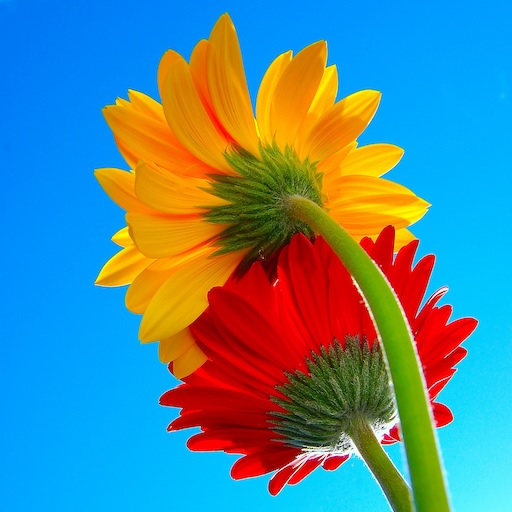

In [14]:
Icv = imread('flowers.jpg')      # opencv format (BGR)
cv2_imshow(Icv)


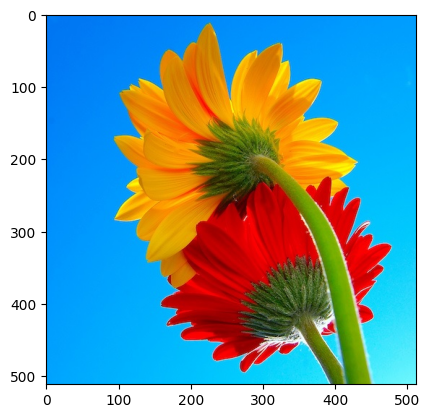

In [15]:
I = Icv[:,:,[2,1,0]]             # BGR to RGB conversion
plt.imshow(I)
plt.show()

# Canales de Color

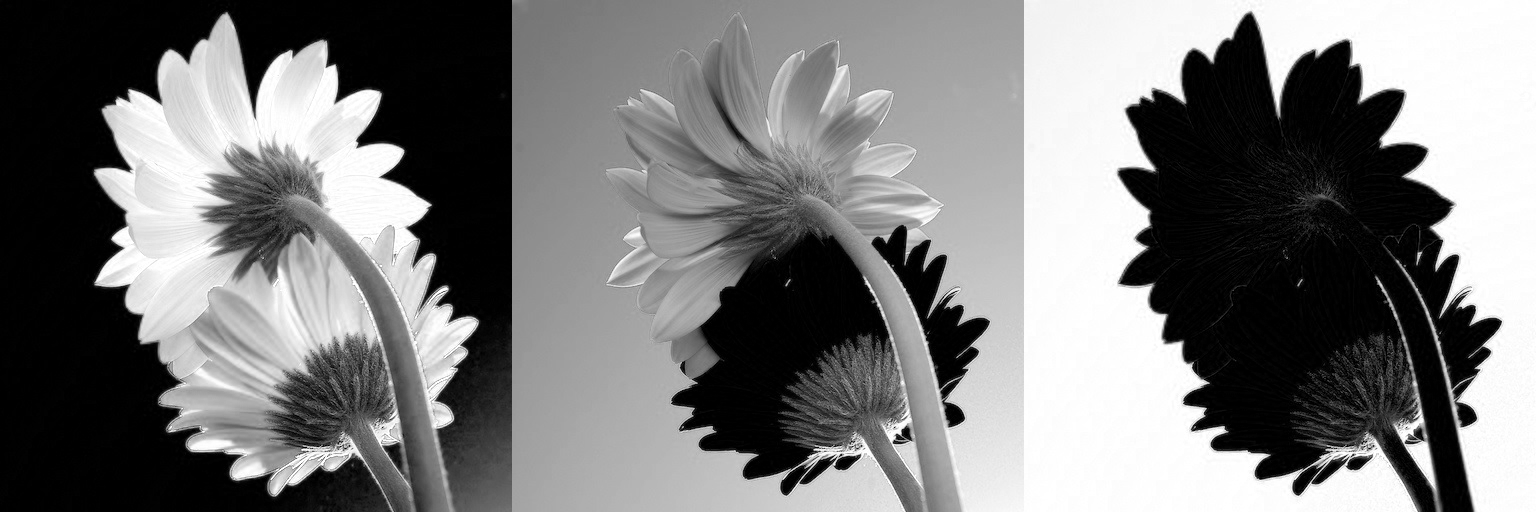

In [16]:
R = I[:,:,0]
G = I[:,:,1]
B = I[:,:,2]
RGB = np.concatenate((R,G,B),axis=1)
cv2_imshow(RGB)

# Conversion a blanco y negro (tonos de gris)

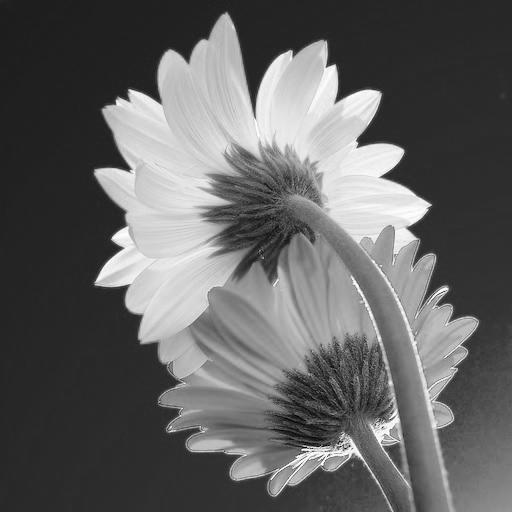

In [17]:
Rd = R.astype(float)
Gd = G.astype(float)
Bd = B.astype(float)
# weighted average
#k  = (1/3,1/3,1/3)
k  = (0.75,0.25,0)
Zd = k[0]*Rd+k[1]*Gd+k[2]*Bd
Z  = Zd.astype(int)
cv2_imshow(Z)

# Histograma

In [18]:
def imhist(X):
  (N,M) = X.shape
  n = 256
  h = np.zeros((256,))
  for i in range(N):
    for j in range(M):
      x = X[i,j]
      h[x] = h[x]+1
  plt.plot(range(n),h[0:n])
  plt.show()


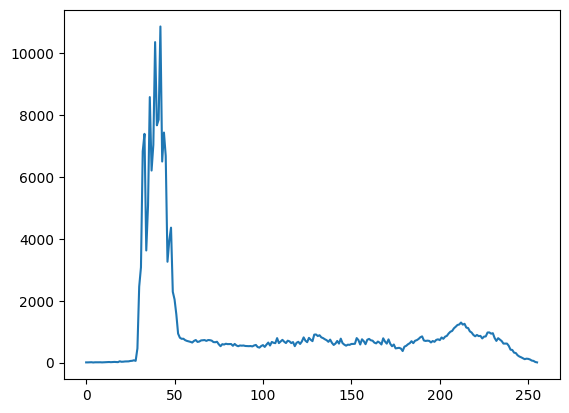

In [19]:
imhist(Z)

# Segmentación de flores rojas

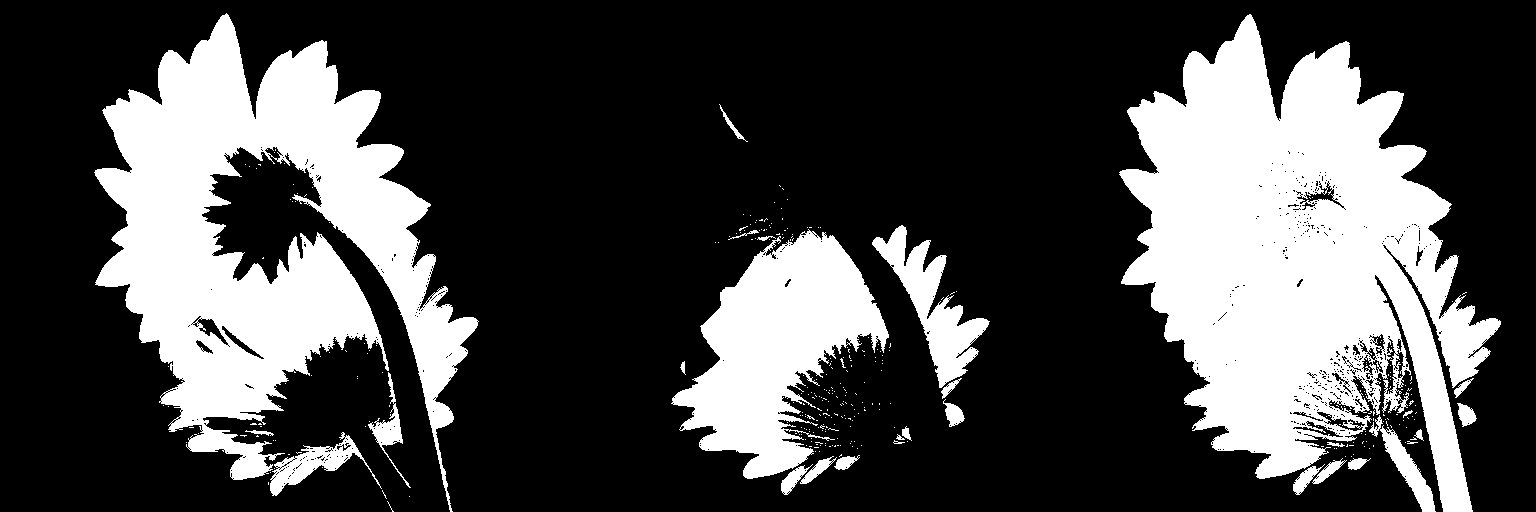

In [20]:
Sr = R>150 #Estos valores se pueden cambiar para obtener diferentes resultados
Sg = G<40
Sb = B<40
Srgb = np.concatenate((Sr,Sg,Sb),axis=1)
cv2_imshow(Srgb*255)

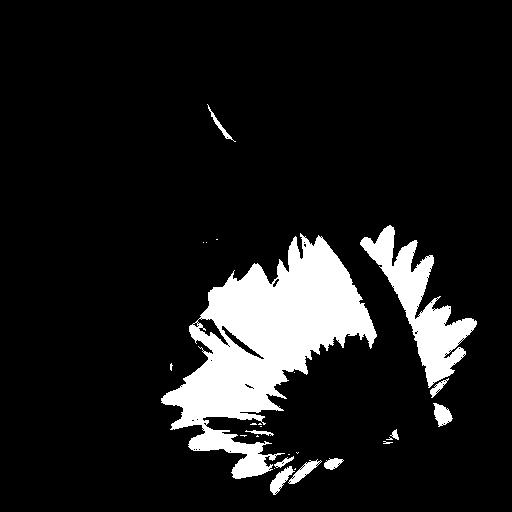

In [21]:
Srg = np.logical_and(Sr,Sg)
S   = np.logical_and(Srg,Sb)
cv2_imshow(S*255)

# Removemos pixeles Aislados


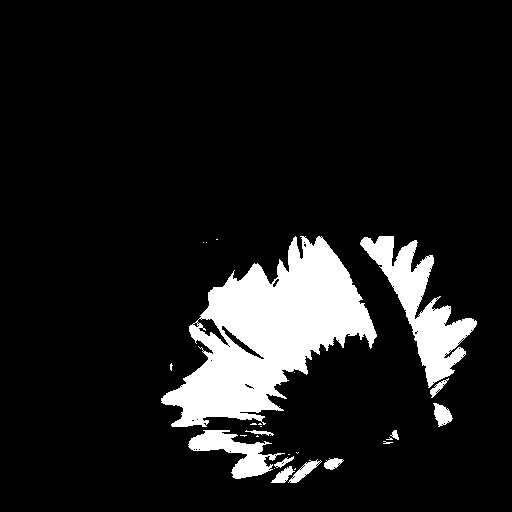

In [22]:
(N,M) = S.shape
Q = S
for i in range(N):
  s = np.sum(S[i,:])
  if s<20:    #Este valor puede hacer más o menos agresiva la operación
    Q[i,:] = 0
cv2_imshow(Q*255)

# Buscamos el área que usa la segmentación

In [23]:
imin = 1000
imax = 0
jmin = 1000
jmax = 0
for i in range(N):
  for j in range(M):
    if Q[i,j]>0:
      if i<imin:
        imin = i
      if i>imax:
        imax = i
      if j<jmin:
        jmin = j
      if j>jmax:
        jmax = j

# Bounding Box

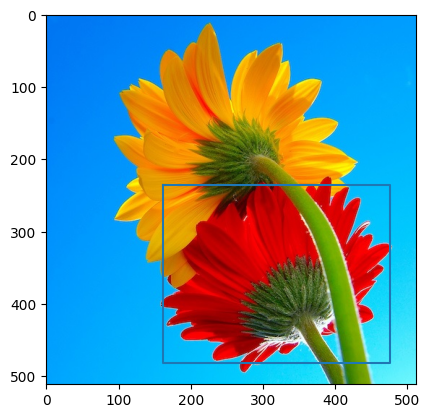

In [24]:
y = [imin,imin,imax,imax,imin]
x = [jmin,jmax,jmax,jmin,jmin]
plt.imshow(I)
plt.plot(x,y)
plt.show()

# Detección de bordes

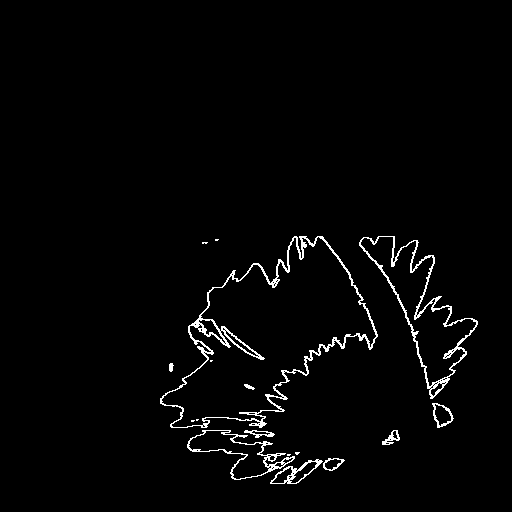

In [25]:
E = np.zeros((N,M),np.uint8)
for i in range(N):
  for j in range(1,M):
    if Q[i,j]!=Q[i,j-1]:
      E[i,j]   = 1
      E[i,j-1] = 1
for i in range(1,N):
  for j in range(M):
    if Q[i-1,j]!=Q[i,j]:
      E[i,j]   = 1
      E[i,j-1] = 1
cv2_imshow(E*255)


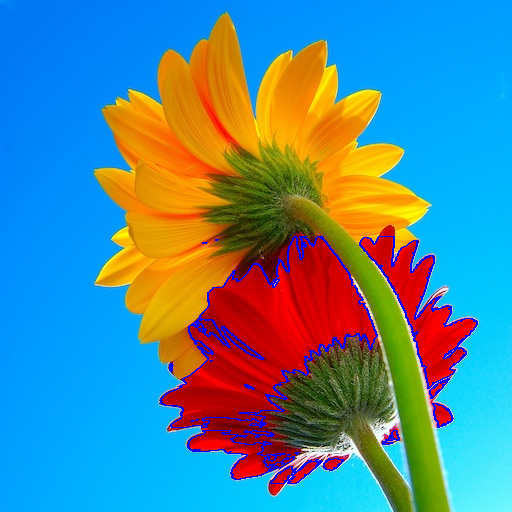

In [26]:
for i in range(N):
  for j in range(M):
    if E[i,j]==1:
      Icv[i,j,:] = [255,0,0]
cv2_imshow(Icv)

# Segmentación de región usando OTSU

Region Detection using OTSU, MSER, etc.


In [27]:
!wget https://www.dropbox.com/scl/fi/tviepftj1jmqgrzrscjtw/N0005_0009.jpg?rlkey=vjhoacfkzvbjl3bjmffoc9ndd&st=e8pfh51z&dl=0
!mv N0005_0009.jpg?rlkey=vjhoacfkzvbjl3bjmffoc9ndd N0005_0009.jpg
!wget https://www.dropbox.com/scl/fi/gop8oggn8fl172b69qgh3/estuche.jpg?rlkey=hnrd8q23akxuy3jwdboom2lw1&st=6o3tszns&dl=0
!mv estuche.jpg?rlkey=hnrd8q23akxuy3jwdboom2lw1 estuche.jpg

--2026-06-18 22:23:37--  https://www.dropbox.com/scl/fi/tviepftj1jmqgrzrscjtw/N0005_0009.jpg?rlkey=vjhoacfkzvbjl3bjmffoc9ndd
Resolving www.dropbox.com (www.dropbox.com)... 162.125.13.18, 2620:100:6031:18::a27d:5112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.13.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc2219ddb0bd4254dcf7b8105684.dl.dropboxusercontent.com/cd/0/inline/DCq_aY4NCbTgOnkAIuGybvC6d562TeKorz33cEIz9vsFXjKSXNQCaBDwm24-opMVLLJkbMaxrXprI0gi3q8HXskBd6BDHC1KHaKX8ZJJSbPIky5X72xt1gYMzwt0-0jpb1c/file# [following]
--2026-06-18 22:23:38--  https://uc2219ddb0bd4254dcf7b8105684.dl.dropboxusercontent.com/cd/0/inline/DCq_aY4NCbTgOnkAIuGybvC6d562TeKorz33cEIz9vsFXjKSXNQCaBDwm24-opMVLLJkbMaxrXprI0gi3q8HXskBd6BDHC1KHaKX8ZJJSbPIky5X72xt1gYMzwt0-0jpb1c/file
Resolving uc2219ddb0bd4254dcf7b8105684.dl.dropboxusercontent.com (uc2219ddb0bd4254dcf7b8105684.dl.dropboxusercontent.com)... 162.125.70.15, 2620:100:6057:15::a27d:d0f
Connecting to u

# Librerías

In [28]:
import matplotlib.pylab as plt
import cv2
import numpy as np
from skimage.morphology import binary_dilation
from skimage.segmentation import clear_border,find_boundaries
from skimage.morphology import disk
from skimage.filters import threshold_otsu, gaussian
from skimage.measure import find_contours
from skimage.morphology import remove_small_holes, remove_small_objects
from skimage.filters import threshold_otsu, gaussian
from skimage.measure import find_contours
from skimage.morphology import binary_closing
from skimage.measure import label, regionprops


In [29]:
from skimage.color import label2rgb
from skimage.measure import label

# (c) Christian Pieringer and Domingo Mery

def binview(img, mask, color='r', dilate_pixels=1):
    """
    Displays a gray or color image 'img' overlaid by color pixels determined a by binary image 'mask'. It is useful to
    display the edges of an image.

    Args:
        img: gray scale image (X-ray)
        mask: binary image that works as mask
        color: string to define pixel color.
                'r': red (default)
                'g': green
                'b': blue
                'y': yellow
                'c': cyan
                'm': magenta
                'k': black
                'w': white

        dilate_pixels (int): Number of pixels used for dilate the mask.

    Returns:
        img_color (ndarray): output image with a mask overlaid.
    """

    # Defines colors
    # colors = {
    #     'r': np.array([255, 0, 0]),
    #     'g': np.array([0, 255, 0]),
    #     'b': np.array([0, 0, 255]),
    #     'y': np.array([255, 255, 0]),
    #     'c': np.array([0, 255, 255]),
    #     'm': np.array([255, 0, 255]),
    #     'k': np.array([0, 0, 0]),
    #     'w': np.array([255, 255, 255])
    # }
    #
    colors = {
        'r': np.array([1, 0, 0]),
        'g': np.array([0, 1, 0]),
        'b': np.array([0, 0, 1]),
        'y': np.array([1, 1, 0]),
        'c': np.array([0, 1, 1]),
        'm': np.array([1, 0, 1]),
        'k': np.array([0, 0, 0]),
        'w': np.array([1, 1, 1])
    }
    # Create a RGB image from grayscale image.
    img_color = np.dstack((img, img, img))

    # Ensure do not modify the original color image and the mask
    img_color = img_color.copy()

    mask_ = mask.copy()
    # mask_ = dilate(mask_, np.ones((g, g), np.uint8))
    mask_ = binary_dilation(mask_, np.ones((dilate_pixels, dilate_pixels)))

    # Now black-out the area of the mask
    # img_fg = bitwise_and(img, img, mask=mask_)

    # Defines the pixel color used for the mask in the figure.
    cc = colors[color]
    #
    # for i in range(3):
    #     img_color[:, :, i] = cc[i] * img_fg

    # remove artifacts connected to image border
    cleared = clear_border(mask_)
    if np.all(cleared):
        mask_ = cleared

    # label image regions
    label_image = label(mask_)
    img_color = label2rgb(label_image, image=img_color, colors=[cc], bg_label=0)

    return img_color  # add(img_color, img_color)


In [30]:
def imhist(X):
  (N,M) = X.shape
  n = 256
  h = np.zeros((256,))
  for i in range(N):
    for j in range(M):
      x = X[i,j]
      h[x] = h[x]+1
  return h


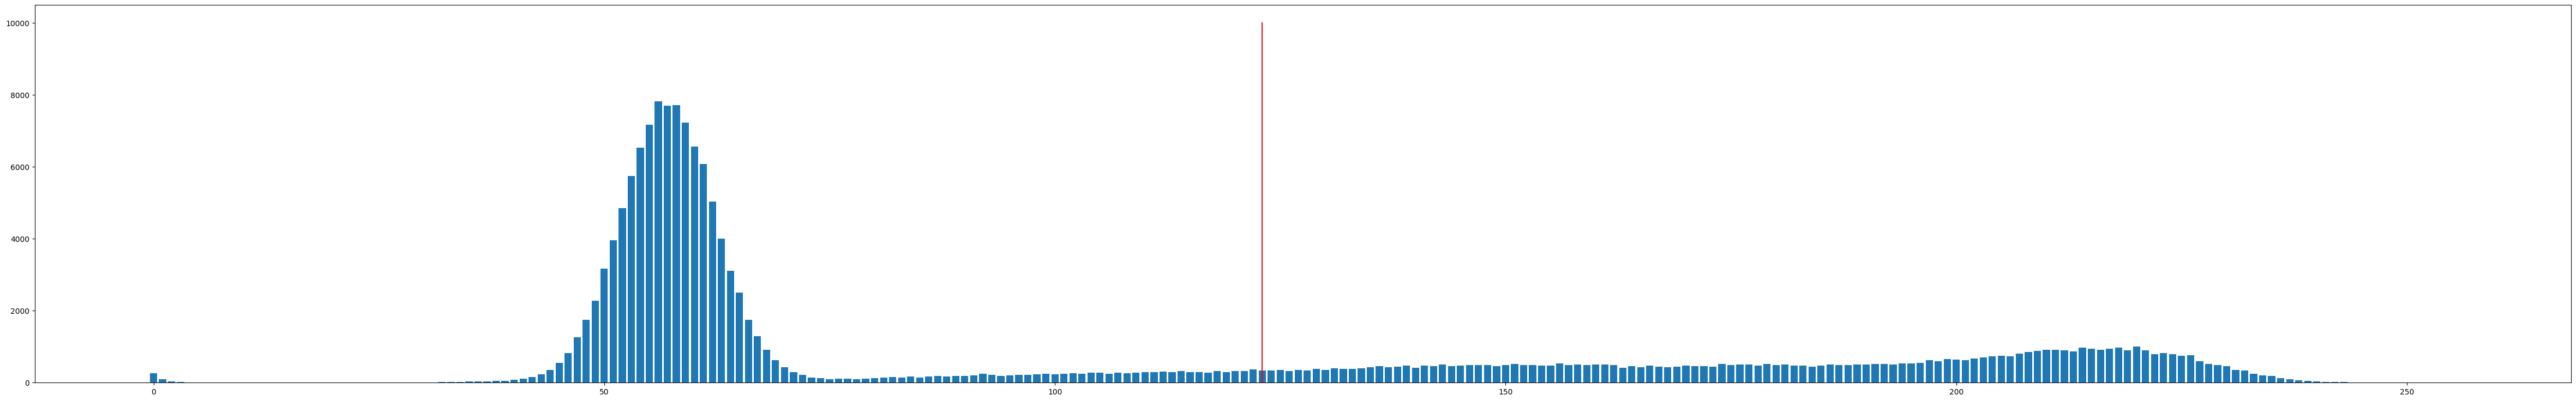

otsu-threshold =  123


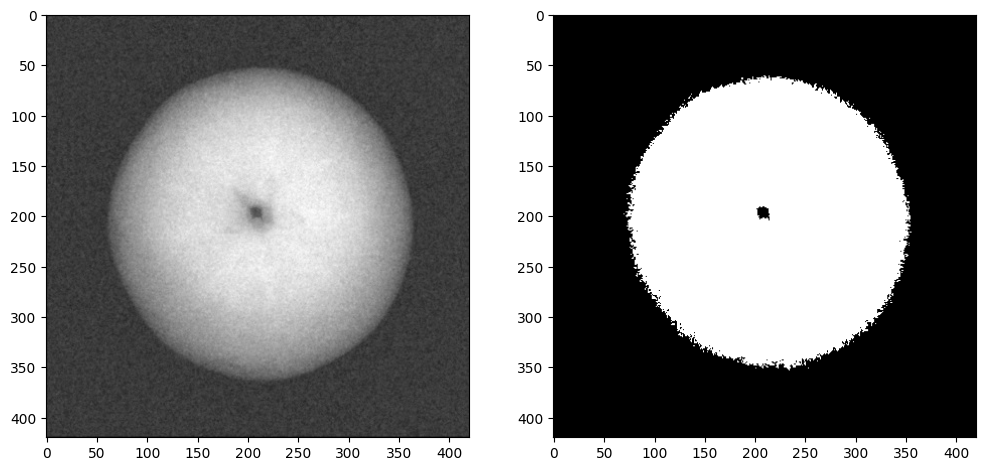

In [32]:
img = cv2.imread('N0005_0009.jpg',0)
h   = imhist(img)
plt.figure(figsize=(60,9))
plt.bar(range(256),h)
th  = threshold_otsu(img)
plt.plot([th,th],[0,10000],c='red')
plt.show()
print('otsu-threshold = ',th)
seg = img > th
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap='gray')
ax[1].imshow(seg,cmap='gray')
plt.show()


## Bimodal Segmentation

In [33]:
def seg_bimodal(img, p=-0.1):
    """

    :param img: numpy array for a gray-scale input image.
    :param p: float to denote the offset of threshold with p between -1 and 1. A
                positive value is used to dilate the segmentation, the negative
                to erode.
    :return: a tuple with the binary image and the contour of the mask.

    """
    img_d = img.astype('double')
    imax = np.max(img_d.flatten())
    imin = np.min(img_d.flatten())
    img_j = (img_d - imin) / (imax - imin)  # Image normalization [0, 1]

    ni = int(np.fix(img_j.shape[0] / 4))
    nj = int(np.fix(img_j.shape[1] / 4))

    # An heuristic method to ensure that the segmented object will
    # be labeled as 1.
    if np.mean(img_j[0:ni, 0:nj].flatten()) > 0.3:
        img_j = 1 - img_j

    # Transform a double image to unit8
    img_jj = (255 * img_j).astype('uint8')

    # Apply Gaussian filtering to remove noise and compute Otsu thresholding.
    # This step improve the thresholding
    img_jj = gaussian(img_jj, 2.0)
    level = threshold_otsu(img_jj)
    mask = img_jj > (level + p)

    a = remove_small_objects(mask, np.fix(len(mask.flatten()) / 100))
    c = binary_closing(a.astype('double'), disk(7))

    # Why 8?
    r = remove_small_holes(c, 8)
    contours = find_contours(r, 0.1)

    return r, contours

In [39]:
img = cv2.imread('N0005_0009.jpg',0)

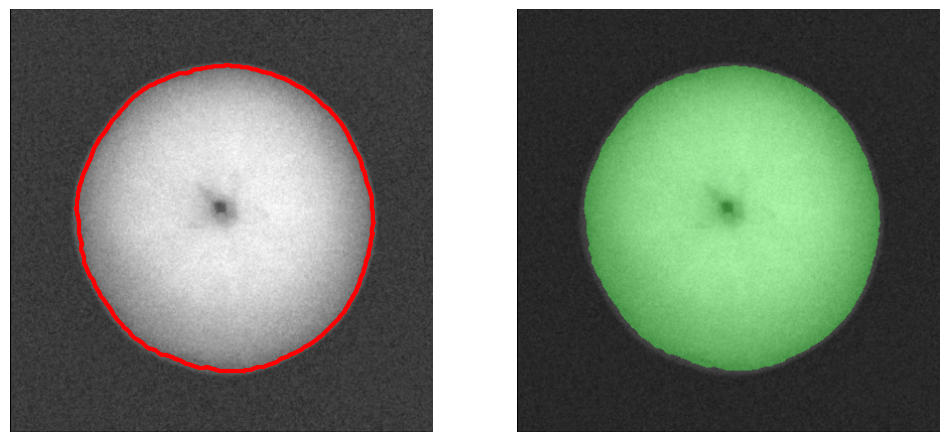

In [40]:
mask, contours = seg_bimodal(img)
seg = binview(img, mask, 'g')

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap='gray')
for n, contour in enumerate(contours):
        ax[0].plot(contour[:, 1], contour[:, 0], color='r', linewidth=3)
ax[0].axis('off')
ax[1].imshow(seg)
ax[1].axis('off')
plt.show()


# Segmentación usando Region- Growing




# Read the X-ray image

In [41]:
!wget https://www.dropbox.com/scl/fi/gop8oggn8fl172b69qgh3/estuche.jpg?rlkey=hnrd8q23akxuy3jwdboom2lw1&st=6o3tszns&dl=0
!mv estuche.jpg?rlkey=hnrd8q23akxuy3jwdboom2lw1 estuche.jpg

--2026-06-18 22:24:38--  https://www.dropbox.com/scl/fi/gop8oggn8fl172b69qgh3/estuche.jpg?rlkey=hnrd8q23akxuy3jwdboom2lw1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.70.18, 2620:100:6057:18::a27d:d12
Connecting to www.dropbox.com (www.dropbox.com)|162.125.70.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uca129aba6c833bf02b18aea6253.dl.dropboxusercontent.com/cd/0/inline/DCohroGsK_nhNXAe9wBzOTE9Pq7wP4pUmitHrRNNx5U_Uv211PRrnPSvNgUEJStYUzxOp2da3kyIu4T-PFCmAuKa1qt-TtH8Vbb2F9JuQMJZbZeKOoncMn4VxAD2333lMj4/file# [following]
--2026-06-18 22:24:40--  https://uca129aba6c833bf02b18aea6253.dl.dropboxusercontent.com/cd/0/inline/DCohroGsK_nhNXAe9wBzOTE9Pq7wP4pUmitHrRNNx5U_Uv211PRrnPSvNgUEJStYUzxOp2da3kyIu4T-PFCmAuKa1qt-TtH8Vbb2F9JuQMJZbZeKOoncMn4VxAD2333lMj4/file
Resolving uca129aba6c833bf02b18aea6253.dl.dropboxusercontent.com (uca129aba6c833bf02b18aea6253.dl.dropboxusercontent.com)... 162.125.70.15, 2620:100:6057:15::a27d:d0f
Connecting to uca12

In [42]:
import matplotlib.pylab as plt
import cv2
import numpy as np


In [43]:
from skimage.morphology import binary_dilation
from skimage.segmentation import clear_border


from skimage.color import label2rgb
from skimage.measure import label

# (c) Christian Pieringer and Domingo Mery

def binview(img, mask, color='r', dilate_pixels=1):
    """
    Displays a gray or color image 'img' overlaid by color pixels determined a by binary image 'mask'. It is useful to
    display the edges of an image.

    Args:
        img: gray scale image (X-ray)
        mask: binary image that works as mask
        color: string to define pixel color.
                'r': red (default)
                'g': green
                'b': blue
                'y': yellow
                'c': cyan
                'm': magenta
                'k': black
                'w': white

        dilate_pixels (int): Number of pixels used for dilate the mask.

    Returns:
        img_color (ndarray): output image with a mask overlaid.
    """

    # Defines colors
    # colors = {
    #     'r': np.array([255, 0, 0]),
    #     'g': np.array([0, 255, 0]),
    #     'b': np.array([0, 0, 255]),
    #     'y': np.array([255, 255, 0]),
    #     'c': np.array([0, 255, 255]),
    #     'm': np.array([255, 0, 255]),
    #     'k': np.array([0, 0, 0]),
    #     'w': np.array([255, 255, 255])
    # }
    #
    colors = {
        'r': np.array([1, 0, 0]),
        'g': np.array([0, 1, 0]),
        'b': np.array([0, 0, 1]),
        'y': np.array([1, 1, 0]),
        'c': np.array([0, 1, 1]),
        'm': np.array([1, 0, 1]),
        'k': np.array([0, 0, 0]),
        'w': np.array([1, 1, 1])
    }
    # Create a RGB image from grayscale image.
    img_color = np.dstack((img, img, img))

    # Ensure do not modify the original color image and the mask
    img_color = img_color.copy()

    mask_ = mask.copy()
    # mask_ = dilate(mask_, np.ones((g, g), np.uint8))
    mask_ = binary_dilation(mask_, np.ones((dilate_pixels, dilate_pixels)))

    # Now black-out the area of the mask
    # img_fg = bitwise_and(img, img, mask=mask_)

    # Defines the pixel color used for the mask in the figure.
    cc = colors[color]
    #
    # for i in range(3):
    #     img_color[:, :, i] = cc[i] * img_fg

    # remove artifacts connected to image border
    cleared = clear_border(mask_)
    if np.all(cleared):
        mask_ = cleared

    # label image regions
    label_image = label(mask_)
    img_color = label2rgb(label_image, image=img_color, colors=[cc], bg_label=0)

    return img_color  # add(img_color, img_color)


In [44]:
from skimage.morphology import flood
from skimage.morphology import binary_dilation

# (c) Christian Pieringer and Domingo Mery


def region_growing(img, seed_point, tolerance=20):
    """
    Args:
        img (ndarray): image
        seed_point (tuple): define the seed point.
        tolerance: a float or int value to define the maximal difference of grayvalues in the region. According to the
                   documentation in scikit-image, if tolerance is provided, adjacent points with values within plus
                   or minus tolerance from the seed point are filled (inclusive).

    Returns:
        mask (ndarray): output binary image
    """
    mask = flood(img, seed_point, tolerance=tolerance)
    mask = binary_dilation(mask, np.ones((3, 3)))

    return mask


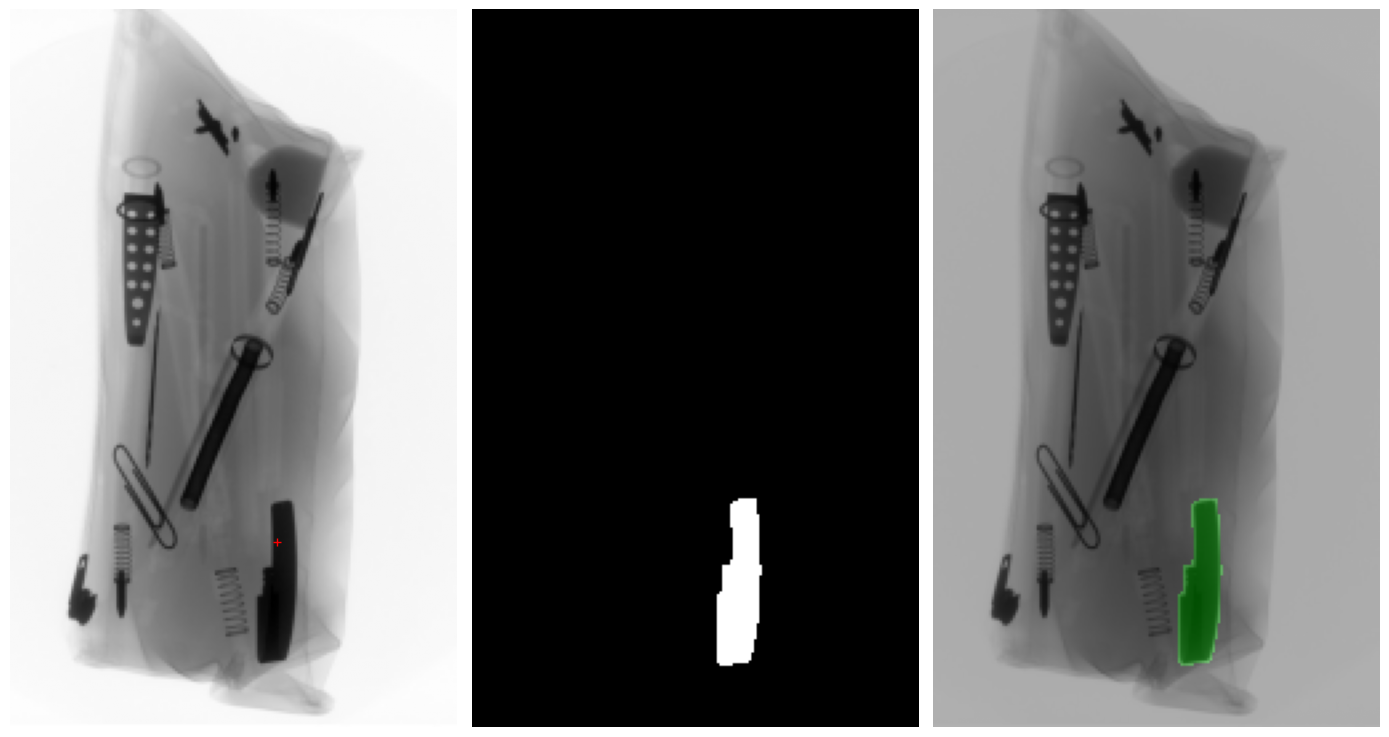

In [52]:
img = cv2.imread('estuche.jpg',0)
img = cv2.resize(img, None, fx=0.35, fy=0.35, interpolation=cv2.INTER_AREA)

th = 40  # threshold
si, sj = (200, 100)  # Seed

mask = region_growing(img, (si, sj), tolerance=th)

seg = binview(img, mask, 'g')

fig, ax = plt.subplots(1, 3, figsize=(14, 8))
ax[0].imshow(img, cmap='gray')
ax[0].plot(sj, si, 'r+')
ax[0].axis('off')
ax[1].imshow(mask, cmap='gray')
ax[1].axis('off')
ax[2].imshow(seg)
ax[2].axis('off')
plt.tight_layout()
plt.show()


# Segmentation using Watershed

Example from
[scikit-image](https://scikit-image.org/docs/dev/auto_examples/segmentation/plot_watershed.html#sphx-glr-auto-examples-segmentation-plot-watershed-py)

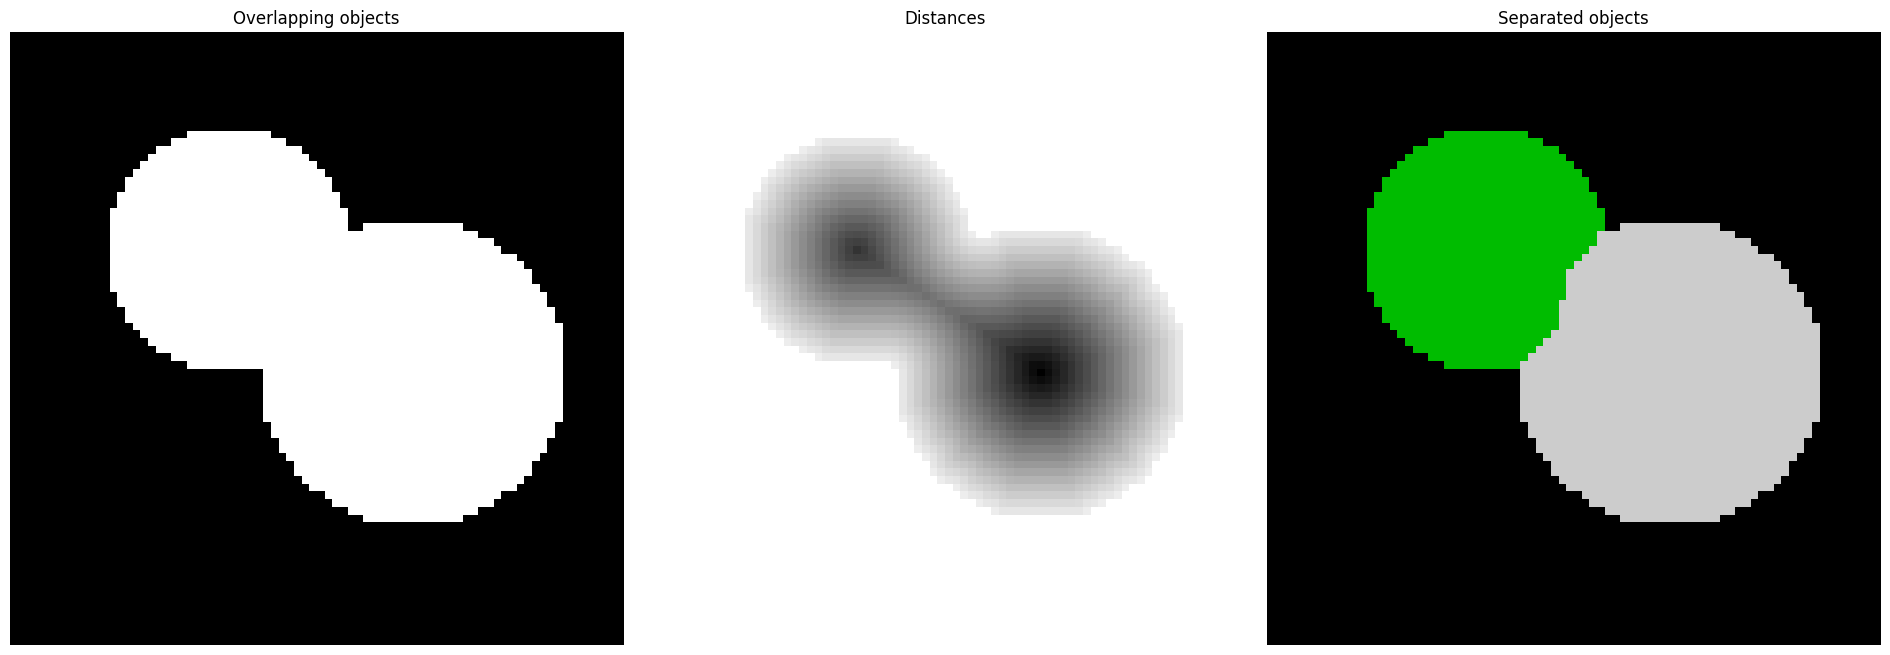

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from skimage.segmentation import watershed
from skimage.feature import peak_local_max


# Generate an initial image with two overlapping circles
N    = 80
x, y = np.indices((N,N))
x1, y1, x2, y2 = 28, 28, 44, 52
r1, r2 = 16, 20
mask_circle1 = (x - x1)**2 + (y - y1)**2 < r1**2
mask_circle2 = (x - x2)**2 + (y - y2)**2 < r2**2
image = np.logical_or(mask_circle1, mask_circle2)

# Now we want to separate the two objects in image
# Generate the markers as local maxima of the distance to the background
distance = ndi.distance_transform_edt(image)
coords = peak_local_max(distance, footprint=np.ones((3, 3)), labels=image)
mask = np.zeros(distance.shape, dtype=bool)
mask[tuple(coords.T)] = True
markers, _ = ndi.label(mask)
labels = watershed(-distance, markers, mask=image)

# Removing infinity
D = -distance
t = N
D[D>t] = - 1
D[D==-1] = np.max(D)


fig, axes = plt.subplots(ncols=3, figsize=(19, 7), sharex=True, sharey=True)
ax = axes.ravel()

ax[0].imshow(image, cmap=plt.cm.gray)
ax[0].set_title('Overlapping objects')
ax[1].imshow(D, cmap=plt.cm.gray)
ax[1].set_title('Distances')
ax[2].imshow(labels, cmap=plt.cm.nipy_spectral)
ax[2].set_title('Separated objects')

for a in ax:
    a.set_axis_off()

fig.tight_layout()
plt.show()

In [59]:
!wget https://www.dropbox.com/scl/fi/8f2ndda68s6e64gc1ncrp/jota.png?rlkey=ymqer1d63o7jx6pu4xaaq2057&st=dbpzlpz8&dl=0
!mv jota.png?rlkey=ymqer1d63o7jx6pu4xaaq2057 jota.png

--2026-06-18 22:29:11--  https://www.dropbox.com/scl/fi/8f2ndda68s6e64gc1ncrp/jota.png?rlkey=ymqer1d63o7jx6pu4xaaq2057
Resolving www.dropbox.com (www.dropbox.com)... 162.125.13.18, 2620:100:6028:18::a27d:4712
Connecting to www.dropbox.com (www.dropbox.com)|162.125.13.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uca968fcfc25aa647387244b898e.dl.dropboxusercontent.com/cd/0/inline/DCqZoX_pHdtZYhY9RxRcrYStqkICv9WeTEKus7W6d6cDNhU9bgbPclWtxPyDVAx5lQRV2TUl7A8pdT-pBDiXY1cggWcTvp4Fon91q-niw7pa_9Um2VA_rE4tIO60IYS2Ryw/file# [following]
--2026-06-18 22:29:12--  https://uca968fcfc25aa647387244b898e.dl.dropboxusercontent.com/cd/0/inline/DCqZoX_pHdtZYhY9RxRcrYStqkICv9WeTEKus7W6d6cDNhU9bgbPclWtxPyDVAx5lQRV2TUl7A8pdT-pBDiXY1cggWcTvp4Fon91q-niw7pa_9Um2VA_rE4tIO60IYS2Ryw/file
Resolving uca968fcfc25aa647387244b898e.dl.dropboxusercontent.com (uca968fcfc25aa647387244b898e.dl.dropboxusercontent.com)... 162.125.70.15, 2620:100:6057:15::a27d:d0f
Connecting to uca968f

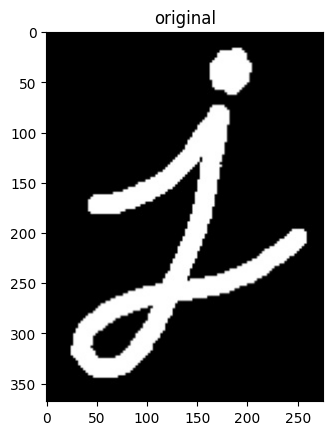

In [60]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('jota.png',0)
plt.imshow(img,cmap='gray')
plt.title('original')
plt.show()


# Erosion

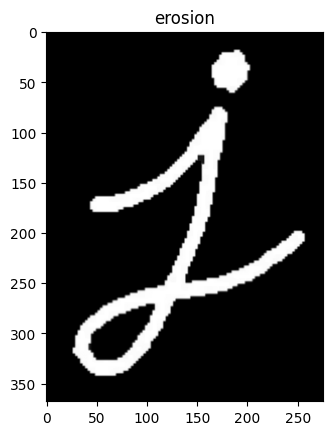

In [61]:
kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.imshow(erosion,cmap='gray')
plt.title('erosion')
plt.show()


# Dilation

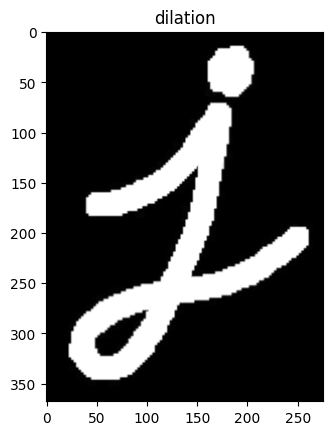

In [63]:
dilation = cv2.dilate(img,kernel,iterations = 1)
plt.imshow(dilation,cmap='gray')
plt.title('dilation')
plt.show()


# Opening

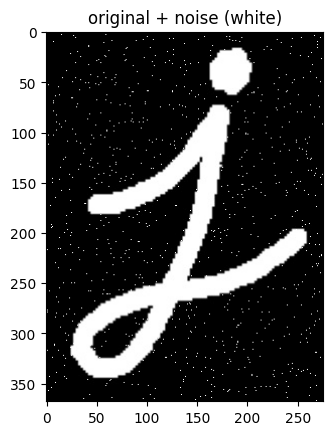

In [64]:
(N,M) = img.shape

img_noise = img.copy()

for i in range(N):
  for j in range(M):
    if np.random.rand()>0.99:
      img_noise[i,j] = 255

plt.imshow(img_noise,cmap='gray')
plt.title('original + noise (white)')
plt.show()

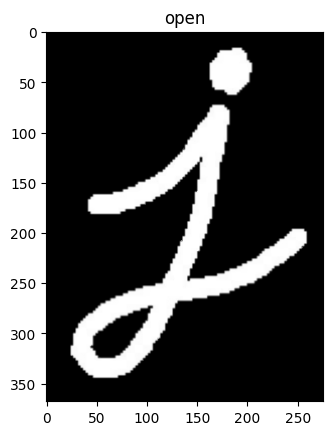

In [65]:
opening = cv2.morphologyEx(img_noise, cv2.MORPH_OPEN, kernel)
plt.imshow(opening,cmap='gray')
plt.title('open')
plt.show()

# Closing

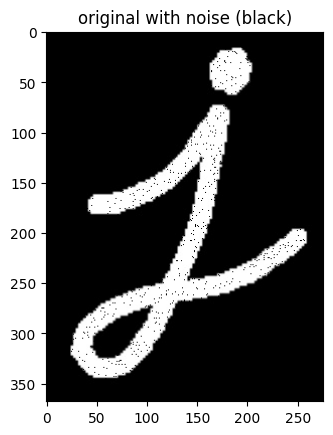

In [66]:
(N,M) = img.shape

img_noise = img.copy()

for i in range(N):
  for j in range(M):
    if np.random.rand()>0.97:
      img_noise[i,j] = 0

plt.imshow(img_noise,cmap='gray')
plt.title('original with noise (black)')
plt.show()

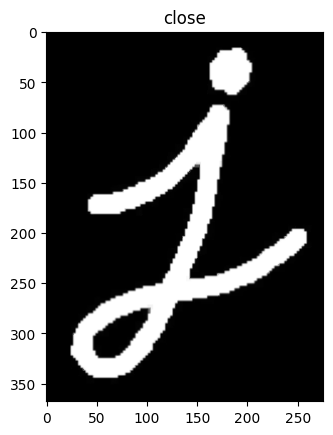

In [67]:
closing = cv2.morphologyEx(img_noise, cv2.MORPH_CLOSE, kernel)
plt.imshow(closing,cmap='gray')
plt.title('close')
plt.show()

# Fill holes

In [68]:
def fillhole(input_image):
    '''
    input gray binary image  get the filled image by floodfill method
    Note: only holes surrounded in the connected regions will be filled.
    :param input_image:
    :return:
    from https://www.programcreek.com/python/example/89425/cv2.floodFill
    '''
    im_flood_fill = input_image.copy()
    h, w = input_image.shape[:2]
    mask = np.zeros((h + 2, w + 2), np.uint8)
    im_flood_fill = im_flood_fill.astype("uint8")
    cv2.floodFill(im_flood_fill, mask, (0, 0), 255)
    im_flood_fill_inv = cv2.bitwise_not(im_flood_fill)
    img_out = input_image | im_flood_fill_inv
    return img_out

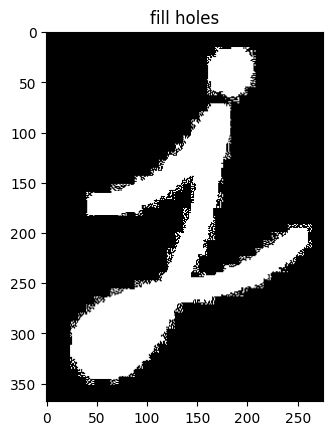

In [69]:
im_fill = fillhole(img)

plt.imshow(im_fill,cmap='gray')
plt.title('fill holes')
plt.show()


# Skeletization

By [N. Reddy](https://medium.com/analytics-vidhya/skeletonization-in-python-using-opencv-b7fa16867331)

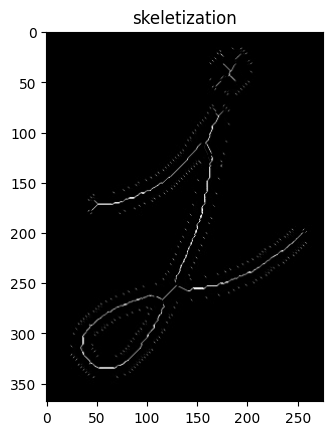

In [70]:

# Step 1: Create an empty skeleton
size = np.size(img)
skel = np.zeros(img.shape, np.uint8)

# Get a Cross Shaped Kernel
element = cv2.getStructuringElement(cv2.MORPH_CROSS, (3,3))

# Repeat steps 2-4
while True:
    #Step 2: Open the image
    open = cv2.morphologyEx(img, cv2.MORPH_OPEN, element)
    #Step 3: Substract open from the original image
    temp = cv2.subtract(img, open)
    #Step 4: Erode the original image and refine the skeleton
    eroded = cv2.erode(img, element)
    skel = cv2.bitwise_or(skel,temp)
    img = eroded.copy()
    # Step 5: If there are no white pixels left ie.. the image has been completely eroded, quit the loop
    if cv2.countNonZero(img)==0:
        break

plt.imshow(skel,cmap='gray')
plt.title('skeletization')
plt.show()
